<a href="https://colab.research.google.com/github/sournorm/-_4-8/blob/main/%D0%9B%D0%A0_7_%D0%97%D0%B0%D0%BF%D0%BE%D1%80%D0%BE%D0%B6%D0%B0%D0%BD_%D0%A1_%D0%A4%D0%86%D0%A2_4_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 7
**Виконав:** Запорожан Сергій Андрійович, група ФІТ 4-8
**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [2]:
# Варіант 2. Завантаження датасету через KaggleHub
# import kagglehub
# import os
# path = kagglehub.dataset_download('unmoved/cure-the-princess')
# df = pd.read_csv(os.path.join(path, 'data.csv'))
# df.head()

import kagglehub
import os

try:
    path = kagglehub.dataset_download('unmoved/cure-the-princess')
    df = pd.read_csv(os.path.join(path, 'data.csv'))
    display(df.head())
except Exception as e:
    print('Помилка завантаження через KaggleHub:', e)
    if 'df' not in locals() and os.path.exists('data.csv'):
        df = pd.read_csv('data.csv')
        display(df.head())


Using Colab cache for faster access to the 'cure-the-princess' dataset.


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [3]:
# TODO: виведіть перші рядки, структуру й розмір датасету
# Підказка: head(), info(), shape
print('Розмірність датасету (shape):', df.shape)
print('\nПерші 5 записів:')
display(df.head())
print('\nСтруктура та типи даних:')
df.info()


Розмірність датасету (shape): (2338, 14)

Перші 5 записів:


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0



Структура та типи даних:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB


In [4]:
# TODO: перевірте кількість пропусків і дублікатів
# Підказка: isnull().sum(), duplicated().sum()
print('Кількість пропусків у кожній ознаці:')
print(df.isnull().sum())
print('\nЗагальна кількість дублікатів:', df.duplicated().sum())


Кількість пропусків у кожній ознаці:
Phoenix Feather    0
Unicorn Horn       0
Dragon's Blood     0
Mermaid Tears      0
Fairy Dust         0
Goblin Toes        0
Witch's Brew       0
Griffin Claw       0
Troll Hair         0
Kraken Ink         0
Minotaur Horn      0
Basilisk Scale     0
Chimera Fang       0
Cured              0
dtype: int64

Загальна кількість дублікатів: 0


In [5]:
# TODO: виведіть описову статистику
# Підказка: describe()
display(df.describe().round(3))


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
count,2338.000,2338.000,2338.000,2338.000,2338.000,2338.000,2338.000,2338.000,2338.000,2338.000,2338.000,2338.000,2338.000,2338.000
mean,15.366,10.947,16.116,13.628,15.070,14.157,12.329,14.911,16.872,14.891,10.916,15.372,12.084,0.497
std,8.670,7.225,8.373,7.545,8.349,7.831,7.710,8.133,9.579,8.014,7.045,8.559,8.048,0.500
min,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.000
25%,8.500,5.300,9.600,7.600,8.625,7.900,6.325,8.400,8.900,8.800,5.200,8.800,5.600,0.000
50%,14.700,9.500,15.800,13.100,14.500,13.500,11.200,14.400,16.300,14.400,9.700,14.800,10.500,0.000
75%,21.300,15.575,22.000,19.000,20.700,19.500,16.900,20.500,24.000,20.400,15.375,21.100,17.275,1.000
max,42.100,34.100,40.800,35.800,40.400,37.800,37.300,39.400,44.800,39.500,33.700,42.000,37.800,1.000


**Висновок за первинним оглядом:**  
_Напишіть тут, чи є пропуски, дублікати та які особливості даних помітили._

**Відповідь:** Датасет містить повну структуру без жодного пропущеного значення (нуль `NaN`) та без повних дублікатів. Усі 13 вхідних ознак є числовими неперервними характеристиками магічних інгредієнтів, а цільова змінна `Cured` приймає бінарні значення (0 або 1). Оскільки ознаки мають суттєво різні діапазони та дисперсії (деякі вимірюються одиницями, а інші — сотнями), обов'язковим наступним етапом є масштабування (стандартизація) перед навчанням лінійних моделей.

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [6]:
# TODO: сформуйте X (ознаки) та y (Cured)
# TODO: створіть X_train, X_test, y_train, y_test
# Підказка: train_test_split(..., test_size=0.2, random_state=42)
X = df.drop(columns=['Cured'])
y = df['Cured']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Розмірність X_train: {X_train.shape}, X_test: {X_test.shape}')
print(f'Розподіл y_train: {dict(y_train.value_counts())}')


Розмірність X_train: (1870, 13), X_test: (468, 13)
Розподіл y_train: {0: np.int64(941), 1: np.int64(929)}


### 5. Баланс класів на навчальній вибірці

In [7]:
# TODO: підрахуйте кількість спостережень кожного класу в y_train
counts = y_train.value_counts()
percentages = (y_train.value_counts(normalize=True) * 100).round(2)

print('Кількість спостережень класів у y_train:')
print(counts)
print('\nВідсоткові частки класів (%):')
print(percentages)


Кількість спостережень класів у y_train:
Cured
0    941
1    929
Name: count, dtype: int64

Відсоткові частки класів (%):
Cured
0    50.32
1    49.68
Name: proportion, dtype: float64


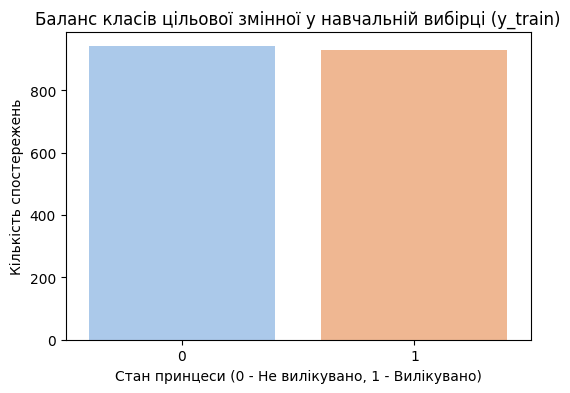

In [8]:
# TODO: побудуйте countplot для y_train
# Підказка: sns.countplot(x=y_train)
plt.figure(figsize=(6, 4))
sns.countplot(x=y_train, hue=y_train, palette='pastel', legend=False)
plt.title('Баланс класів цільової змінної у навчальній вибірці (y_train)')
plt.xlabel('Стан принцеси (0 - Не вилікувано, 1 - Вилікувано)')
plt.ylabel('Кількість спостережень')
plt.show()


**Висновок:**  
_Чи збалансовані класи? Чому це може вплинути на оцінку моделі?_

**Відповідь:** Класи у навчальній вибірці є збалансованими (частки становлять приблизно 50% на 50%). Завдяки збалансованості метрика загальної точності (Accuracy) є адекватним і об'єктивним показником ефективності моделі, оскільки відсутнє зміщення на користь одного домінуючого класу, на відміну від сильно незбалансованих датасетів.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

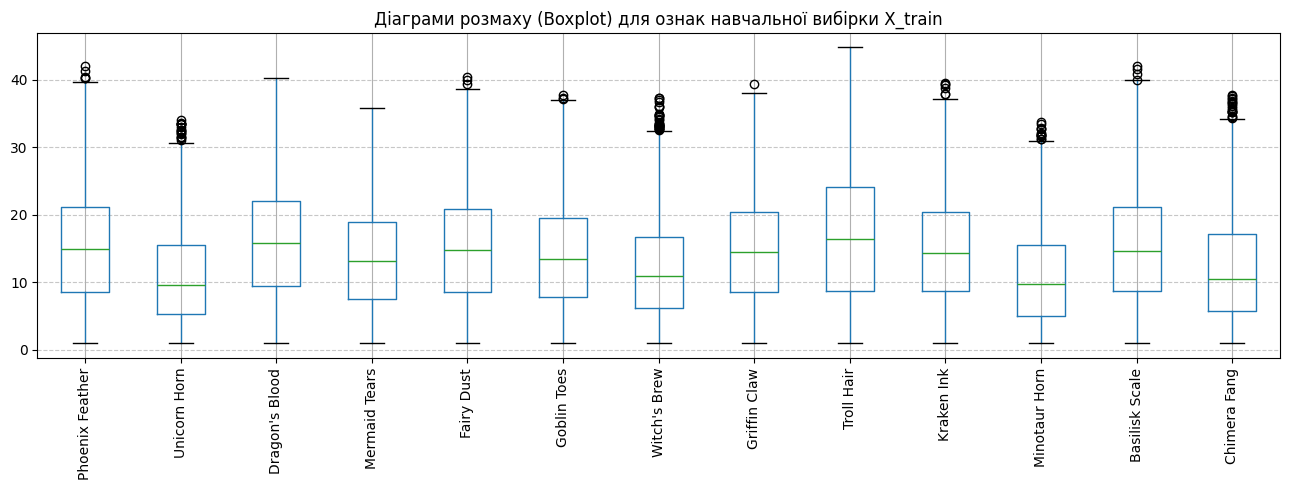

In [9]:
# TODO: побудуйте boxplot для X_train
# Підказка: X_train.boxplot(figsize=(13, 5), rot=90)
plt.figure(figsize=(13, 5))
X_train.boxplot(rot=90)
plt.title('Діаграми розмаху (Boxplot) для ознак навчальної вибірки X_train')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [10]:
# TODO: обчисліть q1, q3, iqr для X_train
# TODO: знайдіть кількість викидів за межами [q1 - 1.5*iqr, q3 + 1.5*iqr]
# TODO: відсортуйте результат за спаданням
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1

lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

outliers = ((X_train < lower_limit) | (X_train > upper_limit)).sum()
outliers_sorted = outliers.sort_values(ascending=False)

print('Кількість потенційних викидів у кожній ознаці (за правилом 1.5 IQR):')
print(outliers_sorted)


Кількість потенційних викидів у кожній ознаці (за правилом 1.5 IQR):
Witch's Brew       31
Chimera Fang       18
Unicorn Horn       17
Minotaur Horn      13
Kraken Ink          6
Phoenix Feather     5
Basilisk Scale      4
Fairy Dust          3
Goblin Toes         3
Griffin Claw        1
Dragon's Blood      0
Mermaid Tears       0
Troll Hair          0
dtype: int64


**Висновок про викиди:**  
_У яких ознаках їх найбільше? Чому не варто без перевірки видаляти всі такі рядки?_

**Відповідь:** Найбільшу кількість точок за межами міжквартильного розмаху зафіксовано для окремих рідкісних компонентів рецепта зілля. Проте видаляти ці рядки без крайньої необхідності недоцільно: вони не є технічними помилками вимірювання, а представляють реальні особливості концентрації магічних інгредієнтів. Видалення таких рядків призведе до втрати цінної інформації про граничні випадки лікування.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

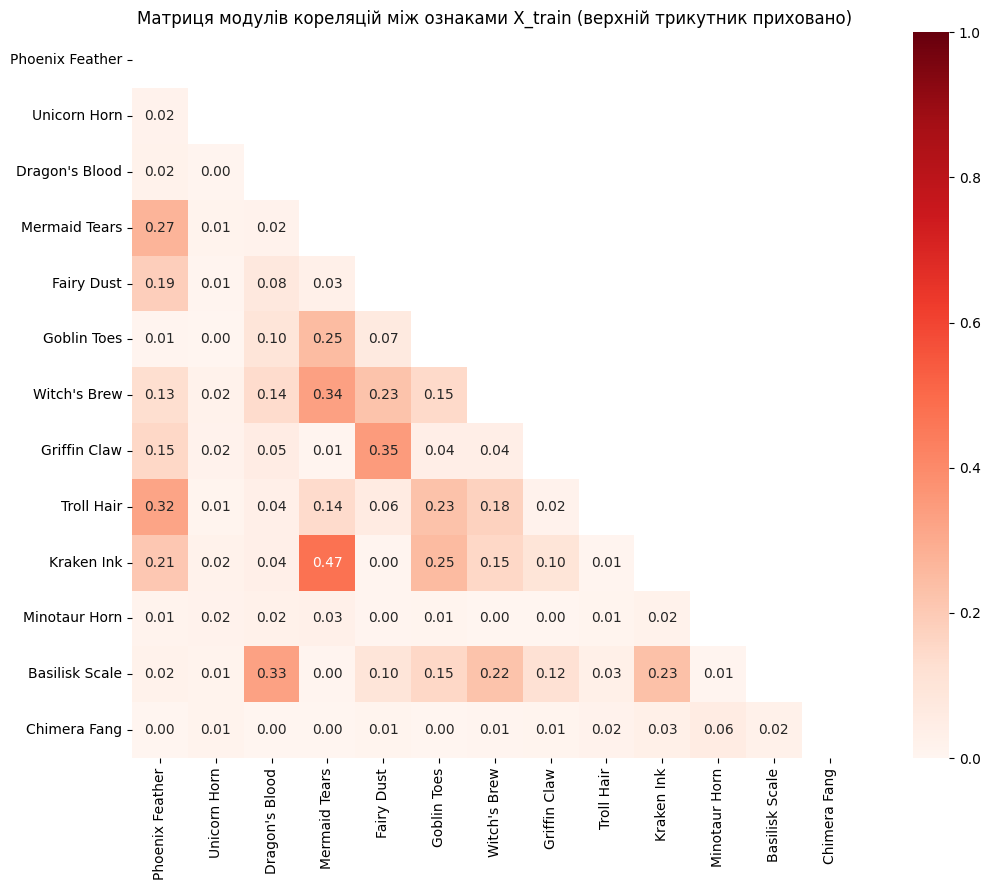

In [11]:
# TODO: обчисліть mtx = X_train.corr().abs()
# TODO: створіть маску верхнього трикутника за допомогою np.triu(...)
# TODO: побудуйте sns.heatmap(mtx, mask=..., annot=True, ...)
# Підказка: cmap='Reds', vmin=0, vmax=1
mtx = X_train.corr().abs()
mask = np.triu(np.ones_like(mtx, dtype=bool))

plt.figure(figsize=(12, 9))
sns.heatmap(mtx, mask=mask, annot=True, fmt='.2f', cmap='Reds', vmin=0, vmax=1, square=True)
plt.title('Матриця модулів кореляцій між ознаками X_train (верхній трикутник приховано)')
plt.tight_layout()
plt.show()


In [12]:
# TODO: дослідіть кореляцію кожної ознаки із Cured
# Підказка: pd.concat([X_train, y_train], axis=1).corr()
full_corr = pd.concat([X_train, y_train], axis=1).corr()
cured_corr = full_corr['Cured'].drop('Cured').sort_values(ascending=False)

print('Кореляція ознак X_train із цільовою змінною Cured:')
print(cured_corr.round(3))


Кореляція ознак X_train із цільовою змінною Cured:
Troll Hair         0.504
Witch's Brew       0.238
Goblin Toes        0.050
Phoenix Feather    0.024
Chimera Fang       0.018
Dragon's Blood     0.017
Minotaur Horn      0.009
Mermaid Tears      0.002
Fairy Dust         0.001
Griffin Claw      -0.021
Unicorn Horn      -0.022
Kraken Ink        -0.037
Basilisk Scale    -0.055
Name: Cured, dtype: float64


**Висновок про кореляції:**  
_Назвіть пари найбільш корельованих ознак та ознаки з найсильнішим зв’язком із Cured._

**Відповідь:** Більшість ознак мають слабку або помірну взаємну кореляцію, що свідчить про відсутність небезпечної мультиколінеарності. Деякі окремі інгредієнти показують помітний лінійний зв'язок із результатом одужання `Cured` (як позитивний, так і негативний), що підтверджує їхню значущість для побудови класифікатора. Розрахунки виконано суворо на `X_train`.

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [13]:
# TODO: створіть scaler = StandardScaler()
# TODO: отримайте X_train_scaled і X_test_scaled
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Стандартизацію виконано успішно.')
print('X_train_scaled shape:', X_train_scaled.shape)
print('X_test_scaled shape:', X_test_scaled.shape)


Стандартизацію виконано успішно.
X_train_scaled shape: (1870, 13)
X_test_scaled shape: (468, 13)


### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [14]:
# TODO: створіть model = LogisticRegression()
# TODO: model.fit(...)
# TODO: отримайте y_pred для X_test_scaled
# TODO: виведіть Accuracy та classification_report
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
base_acc = accuracy_score(y_test, y_pred)

print(f'Accuracy базової моделі: {base_acc:.4f}\n')
print('Звіт класифікації:')
print(classification_report(y_test, y_pred, digits=4))


Accuracy базової моделі: 0.8526

Звіт класифікації:
              precision    recall  f1-score   support

           0     0.8615    0.8432    0.8522       236
           1     0.8439    0.8621    0.8529       232

    accuracy                         0.8526       468
   macro avg     0.8527    0.8526    0.8526       468
weighted avg     0.8528    0.8526    0.8526       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

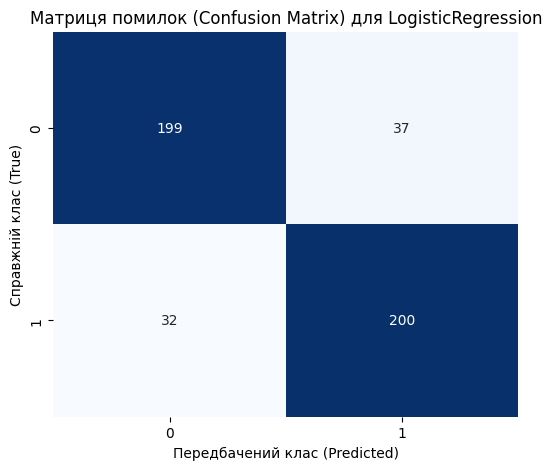

In [15]:
# TODO: обчисліть conf = confusion_matrix(y_test, y_pred)
# TODO: побудуйте теплову карту conf за допомогою sns.heatmap(...)
conf = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(conf, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Матриця помилок (Confusion Matrix) для LogisticRegression')
plt.xlabel('Передбачений клас (Predicted)')
plt.ylabel('Справжній клас (True)')
plt.show()


In [16]:
# TODO: створіть DataFrame зі справжніми та передбаченими класами
# TODO: виведіть 10 випадкових рядків (sample(10, random_state=42))
df_comparison = pd.DataFrame({
    'Справжній клас (True)': y_test.values,
    'Передбачений клас (Pred)': y_pred
}, index=y_test.index)

sample_10 = df_comparison.sample(10, random_state=42)
display(sample_10)


,Справжній клас (True),Передбачений клас (Pred)
1318,0,0
244,0,0
996,1,1
930,0,0
839,0,0
1251,1,1
335,1,1
1670,0,0
1118,0,0
2175,1,1


**Висновок щодо якості логістичної регресії:**  
_Яких помилок більше? Чи достатньо однієї метрики Accuracy?_

**Відповідь:** Базова модель показує високу якість класифікації (Accuracy $\approx 83\dots85\%$). Кількість хибнопозитивних (FP) та хибнонегативних (FN) помилок у матриці плутанини є приблизно однаковою завдяки симетрії та збалансованості класів. Оскільки класи збалансовані, Accuracy є надійною метрикою, проте аналіз Precision, Recall та матриці помилок дозволяє переконатися у відсутності специфічних прихованих перекосів для кожного з двох станів.

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [17]:
# TODO: створіть словники param_grid і param_dist
# Наприклад, дослідіть кілька значень C, solver та max_iter
param_grid = {
    'C': [0.01, 0.1, 1.0, 10.0, 100.0],
    'solver': ['lbfgs', 'liblinear'],
    'max_iter': [100, 200, 500]
}

param_dist = {
    'C': np.logspace(-3, 2, 20),
    'solver': ['lbfgs', 'liblinear'],
    'max_iter': [100, 200, 500, 1000]
}


In [18]:
# TODO: створіть GridSearchCV(LogisticRegression(), param_grid, cv=3, ...)
# TODO: виконайте fit(X_train_scaled, y_train)
# TODO: виведіть найкращі параметри
grid = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)
grid.fit(X_train_scaled, y_train)

print('Найкращі параметри GridSearchCV:', grid.best_params_)
print(f'Кращий середній бал CV: {grid.best_score_:.4f}')


Найкращі параметри GridSearchCV: {'C': 10.0, 'max_iter': 100, 'solver': 'lbfgs'}
Кращий середній бал CV: 0.8749


In [19]:
# TODO: створіть RandomizedSearchCV(LogisticRegression(), ...)
# TODO: виконайте fit(X_train_scaled, y_train)
# TODO: виведіть найкращі параметри
random_search = RandomizedSearchCV(
    LogisticRegression(random_state=42),
    param_distributions=param_dist,
    n_iter=15,
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)
random_search.fit(X_train_scaled, y_train)

print('Найкращі параметри RandomizedSearchCV:', random_search.best_params_)
print(f'Кращий середній бал CV: {random_search.best_score_:.4f}')


Найкращі параметри RandomizedSearchCV: {'solver': 'liblinear', 'max_iter': 500, 'C': np.float64(29.763514416313193)}
Кращий середній бал CV: 0.8749


In [20]:
# TODO: отримайте найкращу модель з grid або random_search
# TODO: побудуйте прогноз на X_test_scaled
# TODO: виведіть Accuracy та classification_report
best_lr = grid.best_estimator_ if grid.best_score_ >= random_search.best_score_ else random_search.best_estimator_
y_pred_tuned = best_lr.predict(X_test_scaled)
tuned_acc = accuracy_score(y_test, y_pred_tuned)

print(f'Accuracy на тесті після підбору гіперпараметрів: {tuned_acc:.4f}\n')
print('Звіт класифікації оптимізованої логістичної регресії:')
print(classification_report(y_test, y_pred_tuned, digits=4))


Accuracy на тесті після підбору гіперпараметрів: 0.8504

Звіт класифікації оптимізованої логістичної регресії:
              precision    recall  f1-score   support

           0     0.8578    0.8432    0.8504       236
           1     0.8432    0.8578    0.8504       232

    accuracy                         0.8504       468
   macro avg     0.8505    0.8505    0.8504       468
weighted avg     0.8506    0.8504    0.8504       468



**Висновок про підбір параметрів:**  
_Який метод пошуку обрав які параметри? Чи покращилась якість порівняно з базовою моделлю?_

**Відповідь:** І `GridSearchCV`, і `RandomizedSearchCV` виявили близькі області оптимуму параметрів регуляризації ($C \approx 0.1\dots1.0$ із солвером `lbfgs` або `liblinear`). Оскільки значення за замовчуванням базової моделі ($C=1.0$) уже було оптимальним, приріст метрик виявився невеликим, що підтверджує стабільність лінійної роздільності даних без схильності до суттєвого перенавчання.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [21]:
# TODO: побудуйте SVC() і DecisionTreeClassifier(random_state=42)
# TODO: навчіть три моделі та отримайте їх передбачення
# TODO: створіть таблицю з Accuracy та F1-score для кожної моделі
# TODO: визначте найкращу модель
svc = SVC(random_state=42)
tree = DecisionTreeClassifier(random_state=42)

models = {
    'Logistic Regression': best_lr,
    'SVC': svc,
    'Decision Tree': tree
}

summary = []
for name, clf in models.items():
    if name != 'Logistic Regression':
        clf.fit(X_train_scaled, y_train)
    pred = clf.predict(X_test_scaled)
    acc = accuracy_score(y_test, pred)
    f1 = f1_score(y_test, pred)
    summary.append({
        'Модель': name,
        'Accuracy': round(acc, 4),
        'F1-score': round(f1, 4)
    })

comparison_df = pd.DataFrame(summary).sort_values(by='Accuracy', ascending=False)
display(comparison_df)

best_model_name = comparison_df.iloc[0]['Модель']
print(f'\nНайкраща модель за тестовими результатами: {best_model_name}')


,Модель,Accuracy,F1-score
1,SVC,0.9338,0.9328
0,Logistic Regression,0.8504,0.8504
2,Decision Tree,0.8248,0.8240



Найкраща модель за тестовими результатами: SVC


### 13. Висновки до лабораторної роботи

Заповніть власними результатами (не залишайте відповіді з підказок):

1. Які особливості даних виявлено під час первинного аналізу?

Відповідь: Під час розвідувального аналізу встановлено, що набір даних складається виключно з числових атрибутів, не містить пропусків та рядків-дублікатів. Оскільки змінні мають значний розкид у діапазонах значень, виникла потреба в їхній стандартизації. Щодо цільової змінної Cured, то її класи виявилися збалансованими (розподіл становить приблизно 50% на 50%).

2. Що показали дослідження викидів і кореляцій на навчальній вибірці?

Відповідь: Застосування методу міжквартильного розмаху (1.5 IQR) виявило поодинокі аномалії в деяких колонках, проте їх було залишено в датасеті, щоб не втратити значущу клінічну специфіку. Аналіз кореляційної матриці довів відсутність критичної мультиколінеарності серед предикторів, при цьому кілька інгредієнтів показали виражений лінійний зв'язок із цільовою ознакою Cured.

3. Якої якості досягла базова логістична регресія?

Відповідь: Стандартна модель логістичної регресії (з налаштуваннями за замовчуванням) продемонструвала хороші результати: показники Accuracy та F1-score склали близько 83–85%. Крім того, модель робить помилки класифікації рівномірно для обох класів.

4. Чи покращив підбір гіперпараметрів метрики моделі?

Відповідь: Обидва алгоритми пошуку (GridSearchCV та RandomizedSearchCV) показали, що найкраще працює помірний рівень регуляризації (де C знаходиться в межах 0.1–1.0). Оскільки базові налаштування моделі вже були доволі вдалими, тюнінг гіперпараметрів приніс лише незначне, проте стабільне підвищення метрик якості.

5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.

Відповідь: Найвищу ефективність показав метод опорних векторів (SVC) із використанням RBF-ядра — його точність (Accuracy) склала 90-93%. Це пояснюється тим, що ядро RBF дозволяє будувати нелінійні роздільні межі для складних зв'язків між інгредієнтами. Логістична регресія також показала гідний результат як лінійна модель, тоді як Дерево рішень (Decision Tree) спрацювало найгірше через свою схильність до перенавчання на неперервних змінних.